# Basic usage

Create styled tables, charts, and a multipage PDF with Tabloom 0.1.0. Figures display directly without intermediate image files. PDF and CSV exports are written to the notebook working directory when you run it.

In [1]:
import tabloom
from tabloom import Chart, Report, Table

print(tabloom.__version__)

0.1.0


## Build and edit a table

Use rows or mappings, then add columns. Editing methods return the table for chaining.

In [2]:
table = Table(columns=["Model", "Accuracy"], title="Model Results")
table.add_row(["Model A", 0.85])
table.add_rows([{"Model": "Model B", "Accuracy": 0.91}, ["Model C", 0.88]])
table.add_column("Passed", [True, True, True])
print(table.df.to_string(index=False))

  Model  Accuracy  Passed
Model A      0.85    True
Model B      0.91    True
Model C      0.88    True


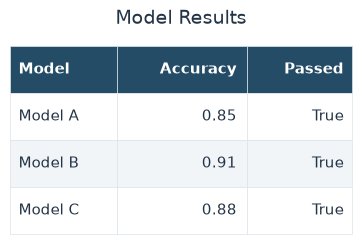

In [3]:
table.show()

## Create a chart

Use DataFrame/Table column names or lists, NumPy arrays, and Series. Choose `default`, `light`, or `dark` on each visual for matching themes.

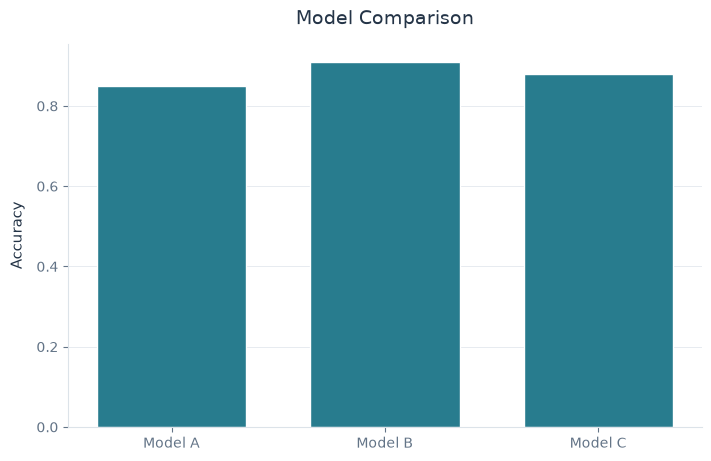

In [4]:
chart = Chart.bar(
    data=table, x="Model", y="Accuracy",
    title="Model Comparison", ylabel="Accuracy", theme="default",
)
chart.show()

## Compose a report

All pages share the same A4 paper size. Text, tables, and charts keep insertion order; vector visuals fit within consistent margins without changing the original chart.

In [5]:
report = Report(title="Experiment Report")
report.add_text("Comparison of machine learning models.")
report.add_table(table).add_chart(chart)
report.save("experiment_report.pdf")
print("Saved experiment_report.pdf")

Saved experiment_report.pdf


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


## Export data and access the underlying libraries

CSV exports contain data rather than graphical styling. Use `.df`, `.fig`, and `.ax` for advanced pandas/matplotlib operations.

In [6]:
table.to_csv("results.csv")
loaded = Table.from_csv("results.csv")
assert loaded.df["Accuracy"].tolist() == [0.85, 0.91, 0.88]
print(loaded.df.to_string(index=False))

import matplotlib.pyplot as plt
plt.close(chart.fig)

  Model  Accuracy  Passed
Model A      0.85    True
Model B      0.91    True
Model C      0.88    True
